In [1]:
# Tratamiento de datos
import numpy as np
import pandas as pd

# Gráficos
import matplotlib.pyplot as plt

# Preprocesado y modelado
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from numpy import linalg as LA

In [6]:
# Cargar la base de datos Iris
df_original = pd.read_csv("C:/Users/gus6e/OneDrive/Downloads/iris.csv")

df_original

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Virginica
146,6.3,2.5,5.0,1.9,Virginica
147,6.5,3.0,5.2,2.0,Virginica
148,6.2,3.4,5.4,2.3,Virginica


In [7]:
# Separar la variable categórica
variety = df_original["variety"]

# Crear DataFrame únicamente con variables numéricas
df = df_original.drop(columns=["variety"])

df

,sepal.length,sepal.width,petal.length,petal.width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [8]:
# Determinar el número de renglones de la base de datos
index = df.index
renglones = len(index)

renglones

150

In [9]:
# Estandarización de las variables
df2 = StandardScaler().fit_transform(df)

df2

array([[-9.00681170e-01,  1.01900435e+00, -1.34022653e+00,
        -1.31544430e+00],
       [-1.14301691e+00, -1.31979479e-01, -1.34022653e+00,
        -1.31544430e+00],
       [-1.38535265e+00,  3.28414053e-01, -1.39706395e+00,
        -1.31544430e+00],
       [-1.50652052e+00,  9.82172869e-02, -1.28338910e+00,
        -1.31544430e+00],
       [-1.02184904e+00,  1.24920112e+00, -1.34022653e+00,
        -1.31544430e+00],
       [-5.37177559e-01,  1.93979142e+00, -1.16971425e+00,
        -1.05217993e+00],
       [-1.50652052e+00,  7.88807586e-01, -1.34022653e+00,
        -1.18381211e+00],
       [-1.02184904e+00,  7.88807586e-01, -1.28338910e+00,
        -1.31544430e+00],
       [-1.74885626e+00, -3.62176246e-01, -1.34022653e+00,
        -1.31544430e+00],
       [-1.14301691e+00,  9.82172869e-02, -1.28338910e+00,
        -1.44707648e+00],
       [-5.37177559e-01,  1.47939788e+00, -1.28338910e+00,
        -1.31544430e+00],
       [-1.26418478e+00,  7.88807586e-01, -1.22655167e+00,
      

In [10]:
# Calcular la matriz de correlaciones para la matriz transformada
A = (1/renglones) * np.dot(df2.T, df2)

A

array([[ 1.        , -0.11756978,  0.87175378,  0.81794113],
       [-0.11756978,  1.        , -0.4284401 , -0.36612593],
       [ 0.87175378, -0.4284401 ,  1.        ,  0.96286543],
       [ 0.81794113, -0.36612593,  0.96286543,  1.        ]])

In [11]:
# Entrenamiento del modelo de análisis de componentes principales
# con escalado de los datos

pca_pipe = make_pipeline(
    StandardScaler(),
    PCA()
)

pca_pipe.fit(df)

# Se extrae el modelo entrenado del pipeline
modelo_pca = pca_pipe.named_steps["pca"]

In [12]:
# Eigenvalores

print("Eigenvalores")

results = LA.eigvals(A)

print(results)

Eigenvalores
[2.91849782 0.91403047 0.14675688 0.02071484]


In [13]:
# Porcentaje de la varianza explicada por cada componente

print("Porcentaje de varianza explicada por componente")

print(modelo_pca.explained_variance_ratio_)

Porcentaje de varianza explicada por componente
[0.72962445 0.22850762 0.03668922 0.00517871]


In [14]:
# Porcentaje de varianza explicada por los dos primeros componentes

varianza_dos_componentes = (
    modelo_pca.explained_variance_ratio_[0] +
    modelo_pca.explained_variance_ratio_[1]
) * 100

print("Varianza explicada por los dos primeros componentes:")
print(varianza_dos_componentes, "%")

Varianza explicada por los dos primeros componentes:
95.81320720000166 %


In [15]:
# Eigenvectores

print("Eigenvectores por renglón:")

componentes = pd.DataFrame(
    data=modelo_pca.components_,
    columns=df.columns,
    index=["PC1", "PC2", "PC3", "PC4"]
)

componentes

Eigenvectores por renglón:


,sepal.length,sepal.width,petal.length,petal.width
PC1,0.521066,-0.269347,0.580413,0.564857
PC2,0.377418,0.923296,0.024492,0.066942
PC3,0.719566,-0.244382,-0.142126,-0.634273
PC4,-0.261286,0.123510,0.801449,-0.523597


In [16]:
# Proyecciones de las observaciones en los componentes principales

proyecciones = np.dot(
    modelo_pca.components_,
    df2.T
)

proyecciones = pd.DataFrame(
    proyecciones,
    index=["PC1", "PC2", "PC3", "PC4"]
)

proyecciones = proyecciones.transpose()

proyecciones

,PC1,PC2,PC3,PC4
0,-2.264703,0.480027,0.127706,-0.024168
1,-2.080961,-0.674134,0.234609,-0.103007
2,-2.364229,-0.341908,-0.044201,-0.028377
3,-2.299384,-0.597395,-0.091290,0.065956
4,-2.389842,0.646835,-0.015738,0.035923
...,...,...,...,...
145,1.870503,0.386966,-0.256274,-0.389257
146,1.564580,-0.896687,0.026371,-0.220192
147,1.521170,0.269069,-0.180178,-0.119171
148,1.372788,1.011254,-0.933395,-0.026129


In [17]:
# Agregar la especie a las proyecciones

proyecciones["variety"] = variety.values

proyecciones

,PC1,PC2,PC3,PC4,variety
0,-2.264703,0.480027,0.127706,-0.024168,Setosa
1,-2.080961,-0.674134,0.234609,-0.103007,Setosa
2,-2.364229,-0.341908,-0.044201,-0.028377,Setosa
3,-2.299384,-0.597395,-0.091290,0.065956,Setosa
4,-2.389842,0.646835,-0.015738,0.035923,Setosa
...,...,...,...,...,...
145,1.870503,0.386966,-0.256274,-0.389257,Virginica
146,1.564580,-0.896687,0.026371,-0.220192,Virginica
147,1.521170,0.269069,-0.180178,-0.119171,Virginica
148,1.372788,1.011254,-0.933395,-0.026129,Virginica


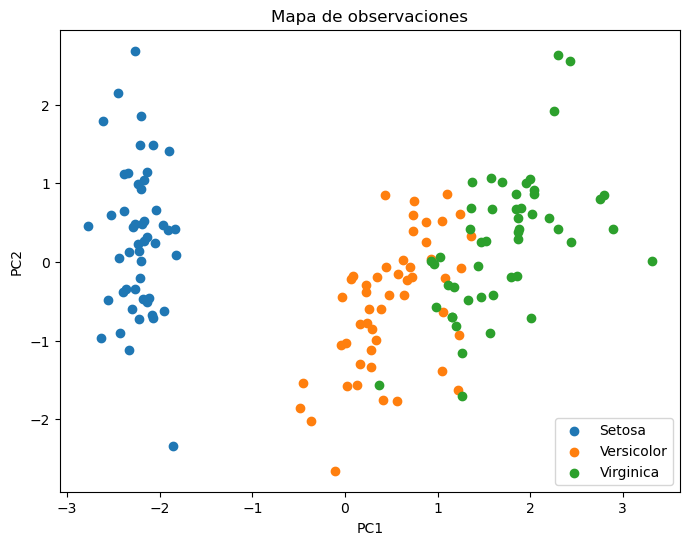

In [18]:
fig, ax = plt.subplots(figsize=(8,6))

for especie in proyecciones["variety"].unique():
    
    datos = proyecciones[
        proyecciones["variety"] == especie
    ]
    
    ax.scatter(
        datos["PC1"],
        datos["PC2"],
        label=especie
    )

ax.set_title("Mapa de observaciones")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend()

plt.show()

In [19]:
# Obtener únicamente los dos primeros componentes
# para elaborar el mapa de factores

componentes_2 = pd.DataFrame(
    data=modelo_pca.components_,
    columns=df.columns,
    index=["PC1", "PC2", "PC3", "PC4"]
)

componentes_2 = componentes_2.iloc[0:2, :]

componentes_2 = componentes_2.T

componentes_2

,PC1,PC2
sepal.length,0.521066,0.377418
sepal.width,-0.269347,0.923296
petal.length,0.580413,0.024492
petal.width,0.564857,0.066942


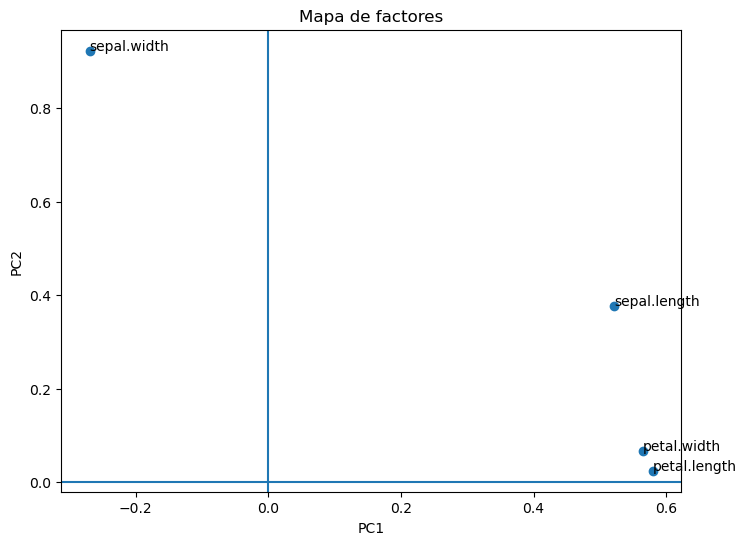

In [20]:
# Mapa de factores

x = componentes_2.iloc[:,0]
y = componentes_2.iloc[:,1]
z = componentes_2.index

x = x.to_numpy()
y = y.to_numpy()

fig, ax = plt.subplots(figsize=(8,6))

ax.set_title("Mapa de factores")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")

ax.scatter(x, y)

for i, txt in enumerate(z):
    ax.annotate(txt, (x[i], y[i]))

plt.axhline(0)
plt.axvline(0)

plt.show()

In [21]:
# Revisar algunos casos específicos del DataFrame

df_original.groupby("variety").head(3)

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
50,7.0,3.2,4.7,1.4,Versicolor
51,6.4,3.2,4.5,1.5,Versicolor
52,6.9,3.1,4.9,1.5,Versicolor
100,6.3,3.3,6.0,2.5,Virginica
101,5.8,2.7,5.1,1.9,Virginica
102,7.1,3.0,5.9,2.1,Virginica


In [22]:
# Promedio de las variables para cada especie

df_original.groupby("variety").mean()

,sepal.length,sepal.width,petal.length,petal.width
variety,,,,
Setosa,5.006,3.428,1.462,0.246
Versicolor,5.936,2.770,4.260,1.326
Virginica,6.588,2.974,5.552,2.026
